# Stage 5 — Uplift (Causal) Model

Estimates the *incremental* effect of being targeted by a coupon campaign — not just who
redeems, but who buys the couponed products **because** they were targeted, versus who
would have bought them anyway. Uses the full active population (treated **and** control),
trained on campaigns 8 and 13, evaluated on campaign 18.

This is observational data: households were not randomly assigned to be targeted (Stages
2-3 established this repeatedly — targeting favors heavy, engaged, already-coupon-using
shoppers). Everything in this notebook is an attempt to *adjust for* that selection bias,
not an attempt to pretend it isn't there. The closing section is explicit about what this
can and can't actually prove.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
import lightgbm as lgb
import xgboost as xgb
from sklearn.calibration import CalibratedClassifierCV

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
sns.set_theme(style="white")
PALETTE = sns.color_palette("colorblind")


## 1. Population, outcomes, and features

Population: **all active households** (treated + control) — every row in the model table,
not just targeted ones. Train = campaigns 8 and 13 pooled; test = campaign 18.

Two outcomes:
- `bought_coupon_product` (new): 1 if the household bought *any* product covered by this
  campaign's coupons during the campaign window (`outcome_coupon_spend > 0`). This is
  defined for control households too, unlike redemption.
- `outcome_coupon_spend` ($): kept as-is, used later for dollar sizing.

Features are the same Stage 2 set used throughout (no segment label, no treated/redeemed/
outcome columns as predictors).


In [2]:
model_table = pd.read_parquet("../data/processed/model_table.parquet")

LABEL_COLS = ["campaign_id", "household_id", "treated", "redeemed", "outcome_spend", "outcome_coupon_spend"]
FEATURE_COLS = [c for c in model_table.columns if c not in LABEL_COLS]

model_table["bought_coupon_product"] = (model_table["outcome_coupon_spend"] > 0).astype(int)

train = model_table[model_table["campaign_id"].isin([8, 13])].reset_index(drop=True)
test = model_table[model_table["campaign_id"] == 18].reset_index(drop=True)

print(f"Train (campaigns 8+13, all active households): {len(train):,} "
      f"({train['treated'].sum():,} treated, {(train['treated']==0).sum():,} control)")
print(f"Test  (campaign 18, all active households):    {len(test):,} "
      f"({test['treated'].sum():,} treated, {(test['treated']==0).sum():,} control)")
print()
print("bought_coupon_product rate, test, by treated:")
print(test.groupby("treated")["bought_coupon_product"].mean())
print(f"Naive difference (treated - control): "
      f"{test.loc[test.treated==1,'bought_coupon_product'].mean() - test.loc[test.treated==0,'bought_coupon_product'].mean():.4f}")


Train (campaigns 8+13, all active households): 4,671 (2,150 treated, 2,521 control)
Test  (campaign 18, all active households):    2,344 (1,129 treated, 1,215 control)

bought_coupon_product rate, test, by treated:
treated
0    0.846914
1    0.970771
Name: bought_coupon_product, dtype: float64
Naive difference (treated - control): 0.1239


### 1a. Base rate by campaign

The same near-saturated pattern shows up in all three campaigns, not just campaign 18 --
useful context for section 7's Qini result and section 8a's alternative outcome.


In [3]:
base_rate_by_campaign = model_table.groupby(["campaign_id", "treated"])["bought_coupon_product"].agg(
    ["mean", "count"]
).rename(columns={"mean": "bought_coupon_product_rate"})
base_rate_by_campaign


bought_coupon_product_rate  count
campaign_id treated                                   
8           0                          0.783936   1245
            1                          0.960930   1075
13          0                          0.789185   1276
            1                          0.967442   1075
18          0                          0.846914   1215
            1                          0.970771   1129

## 2. Treatment propensity model

Logistic regression predicting `P(treated | features)`, fit on the pooled training
population (campaigns 8+13). This is a *different* propensity model from Stage 4 — Stage
4 predicted redemption among the targeted; this one predicts targeting itself, among
everyone, and is used purely for weighting/overlap diagnostics, never as an uplift
feature.

Regularization strength matters more here than usual: a less-regularized model separates
treated/control almost perfectly (features like `earlier_campaigns_count` are strong
predictors of who gets targeted), which pushes propensities toward 0/1 and destroys
overlap. A quick comparison across `C` values shows CV AUC barely changes while the trim
rate changes enormously — so `C` is chosen to preserve overlap, not to maximize
predictive accuracy.


In [4]:
X_train, T_train, groups_train = train[FEATURE_COLS], train["treated"], train["household_id"]
X_test, T_test = test[FEATURE_COLS], test["treated"]
group_kfold = GroupKFold(n_splits=5)


def propensity_cv_check(C):
    aucs = []
    for tr_idx, val_idx in group_kfold.split(X_train, T_train, groups_train):
        pipe = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(C=C, max_iter=2000))])
        pipe.fit(X_train.iloc[tr_idx], T_train.iloc[tr_idx])
        proba = pipe.predict_proba(X_train.iloc[val_idx])[:, 1]
        aucs.append(roc_auc_score(T_train.iloc[val_idx], proba))

    pipe_full = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(C=C, max_iter=2000))])
    pipe_full.fit(X_train, T_train)
    p_test = pipe_full.predict_proba(X_test)[:, 1]
    trimmed = ((p_test < 0.05) | (p_test > 0.95)).sum()
    return np.mean(aucs), trimmed


propensity_c_grid = pd.DataFrame({"C": [0.0005, 0.001, 0.005, 0.01, 0.1]})
propensity_c_grid[["cv_auc", "n_trimmed_at_this_C"]] = propensity_c_grid["C"].apply(
    lambda C: pd.Series(propensity_cv_check(C))
)
propensity_c_grid


,C,cv_auc,n_trimmed_at_this_C
0,0.0005,0.867536,63.0
1,0.0010,0.872885,148.0
2,0.0050,0.882340,442.0
3,0.0100,0.883943,568.0
4,0.1000,0.884219,756.0


In [5]:
PROPENSITY_C = 0.001  # chosen for overlap, not peak CV AUC -- see table above

propensity_model = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(C=PROPENSITY_C, max_iter=2000))])
propensity_model.fit(X_train, T_train)

test["propensity"] = propensity_model.predict_proba(X_test)[:, 1]
train["propensity"] = propensity_model.predict_proba(X_train)[:, 1]


## 3. Overlap histograms and trimming

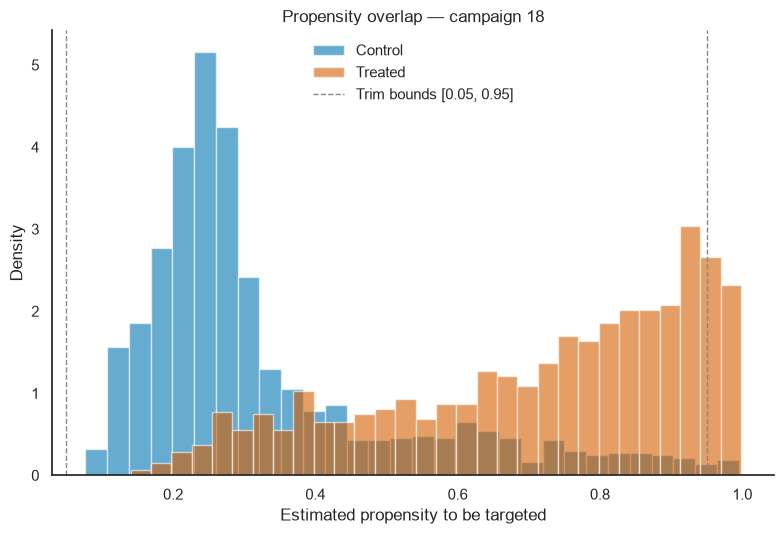

In [6]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.hist(test.loc[test.treated == 0, "propensity"], bins=30, alpha=0.6, label="Control", color=PALETTE[0], density=True)
ax.hist(test.loc[test.treated == 1, "propensity"], bins=30, alpha=0.6, label="Treated", color=PALETTE[3], density=True)
ax.axvline(0.05, color="#888888", linestyle="--", linewidth=1)
ax.axvline(0.95, color="#888888", linestyle="--", linewidth=1, label="Trim bounds [0.05, 0.95]")
ax.set_xlabel("Estimated propensity to be targeted")
ax.set_ylabel("Density")
ax.set_title("Propensity overlap — campaign 18")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


In [7]:
trim_mask = (test["propensity"] >= 0.05) & (test["propensity"] <= 0.95)
n_trimmed = (~trim_mask).sum()
print(f"Campaign 18: {n_trimmed} of {len(test)} households trimmed ({n_trimmed/len(test):.1%}) for propensity outside [0.05, 0.95]")
print(f"  of which treated: {((~trim_mask) & (test.treated==1)).sum()}, control: {((~trim_mask) & (test.treated==0)).sum()}")

segments = pd.read_parquet("../data/processed/segments.parquet")
test = test.merge(segments[["household_id", "segment_name"]], on="household_id", how="left")

trim_by_segment = pd.DataFrame({
    "total": test.groupby("segment_name").size(),
    "trimmed": test.loc[~trim_mask].groupby("segment_name").size(),
}).fillna(0).astype(int)
trim_by_segment["pct_trimmed"] = (trim_by_segment["trimmed"] / trim_by_segment["total"] * 100).round(1)
trim_by_segment


Campaign 18: 148 of 2344 households trimmed (6.3%) for propensity outside [0.05, 0.95]
  of which treated: 139, control: 9


,total,trimmed,pct_trimmed
segment_name,,,
Frequent fuel & grocery shoppers,504,33,6.5
"Lapsing, low engagement",399,0,0.0
"Light, occasional shoppers",318,0,0.0
Loyal big-basket / coupon power users,266,88,33.1
Rising spenders,857,27,3.2


**A third of the "Loyal big-basket" segment gets trimmed** (88 of 266, 33%) — directly
consistent with Stage 3's finding that this segment has almost no control group (25
households) to begin with; its propensity scores skew so high that a third of it falls
outside usable overlap. Rising spenders and Frequent fuel & grocery shoppers lose only
3-7%. Lapsing and Light lose essentially none — their problem (from Stage 3) was too few
*treated* households, not extreme propensities, so none of them get trimmed here.

All downstream overlap-dependent analysis (balance, naive/IPW ATE) uses the **trimmed**
campaign 18 population; the Qini curve and decile table use the **full** population
(standard practice for ranking evaluation), with the overlap caveat repeated wherever it
matters.


## 4. Covariate balance — before and after IPW weighting

Standardized mean difference (SMD) for every feature, treated vs. control, on the trimmed
campaign 18 population — before weighting, and after inverse-propensity weighting (IPW
weight = 1/p for treated, 1/(1-p) for control). Target: |SMD| < 0.1.


In [8]:
kept = test.loc[trim_mask].reset_index(drop=True)
ipw_weight = np.where(kept["treated"] == 1, 1 / kept["propensity"], 1 / (1 - kept["propensity"]))
kept["ipw"] = ipw_weight


def smd(x, t, w=None):
    if w is None:
        m1, m0 = x[t == 1].mean(), x[t == 0].mean()
        s1, s0 = x[t == 1].std(), x[t == 0].std()
    else:
        w1, w0 = w[t == 1], w[t == 0]
        m1 = np.average(x[t == 1], weights=w1)
        m0 = np.average(x[t == 0], weights=w0)
        s1 = np.sqrt(np.average((x[t == 1] - m1) ** 2, weights=w1))
        s0 = np.sqrt(np.average((x[t == 0] - m0) ** 2, weights=w0))
    pooled_std = np.sqrt((s1 ** 2 + s0 ** 2) / 2)
    return (m1 - m0) / pooled_std if pooled_std > 0 else 0.0


t_arr = kept["treated"].to_numpy()
w_arr = kept["ipw"].to_numpy()
balance = pd.DataFrame({
    "smd_before": {f: smd(kept[f].to_numpy(), t_arr) for f in FEATURE_COLS},
    "smd_after": {f: smd(kept[f].to_numpy(), t_arr, w_arr) for f in FEATURE_COLS},
})
balance["abs_before"] = balance["smd_before"].abs()
balance["abs_after"] = balance["smd_after"].abs()
balance = balance.sort_values("abs_before", ascending=False)

print(f"Features with |SMD| > 0.1 -- before: {(balance['abs_before'] > 0.1).sum()} of {len(balance)}, "
      f"after: {(balance['abs_after'] > 0.1).sum()} of {len(balance)}")
print(f"Max |SMD| -- before: {balance['abs_before'].max():.3f}, after: {balance['abs_after'].max():.3f}")
balance.head(15)


Features with |SMD| > 0.1 -- before: 50 of 64, after: 21 of 64
Max |SMD| -- before: 1.443, after: 0.529


,smd_before,smd_after,abs_before,abs_after
earlier_campaigns_count,1.443114,0.528562,1.443114,0.528562
monetary_spend,1.067272,0.306458,1.067272,0.306458
frequency_baskets,0.981573,0.335669,0.981573,0.335669
has_demographics,0.941919,0.203871,0.941919,0.203871
kids_count_0,0.754839,0.217630,0.754839,0.217630
concurrent_campaigns_count,0.679153,0.232282,0.679153,0.232282
recency_days,-0.672427,-0.260194,0.672427,0.260194
home_ownership_Homeowner,0.630827,0.161950,0.630827,0.161950
household_size_2,0.554511,0.183799,0.554511,0.183799
marital_status_Married,0.512724,0.187720,0.512724,0.187720


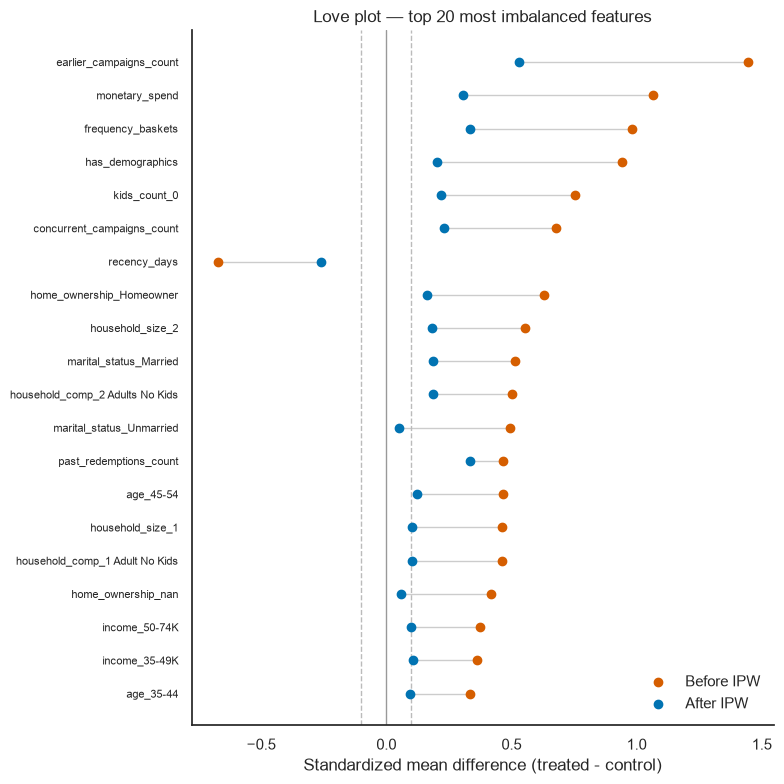

In [9]:
top_imbalanced = balance.head(20).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 8))
y_pos = np.arange(len(top_imbalanced))
ax.scatter(top_imbalanced["smd_before"], y_pos, color=PALETTE[3], label="Before IPW", zorder=3)
ax.scatter(top_imbalanced["smd_after"], y_pos, color=PALETTE[0], label="After IPW", zorder=3)
for i, (b, a) in enumerate(zip(top_imbalanced["smd_before"], top_imbalanced["smd_after"])):
    ax.plot([b, a], [i, i], color="#cccccc", zorder=1, linewidth=1)

ax.axvline(0, color="#999999", linewidth=1)
ax.axvline(0.1, color="#bbbbbb", linestyle="--", linewidth=1)
ax.axvline(-0.1, color="#bbbbbb", linestyle="--", linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(top_imbalanced.index, fontsize=8)
ax.set_xlabel("Standardized mean difference (treated - control)")
ax.set_title("Love plot — top 20 most imbalanced features")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


**IPW helps a lot but doesn't fully close the gap.** The number of badly-imbalanced
features (|SMD| > 0.1) drops from 50 of 64 to 21 of 64, and the worst offender
(`earlier_campaigns_count`) falls from an SMD of 1.44 (a huge imbalance) to 0.53 — still
far from the 0.1 target. This is an honest signal that targeting selection on prior
campaign history is strong enough that a logistic propensity model, even after weighting,
can't fully equalize the two groups. The naive comparison is clearly unreliable; the IPW
comparison is *better*, not perfect.


### 4a. Which features are still imbalanced after IPW?

The 21 features with |SMD| > 0.1 after weighting, with each feature's prevalence (mean
value -- for a 0/1 dummy this is directly the share of the population with that value)
to help judge how much a given imbalance can be trusted.


In [10]:
still_imbalanced = balance.loc[balance["abs_after"] > 0.1, ["smd_after", "abs_after"]].copy()
still_imbalanced["prevalence_in_kept_population"] = kept[still_imbalanced.index].mean()

DEMOGRAPHIC_PREFIXES = (
    "age_", "income_", "home_ownership_", "marital_status_",
    "household_size_", "household_comp_", "kids_count_",
)
still_imbalanced["category"] = [
    "Demographic dummy" if f.startswith(DEMOGRAPHIC_PREFIXES) or f == "has_demographics" else "Behavioral"
    for f in still_imbalanced.index
]
still_imbalanced.sort_values("abs_after", ascending=False).round(4)


,smd_after,abs_after,prevalence_in_kept_population,category
earlier_campaigns_count,0.5286,0.5286,1.6434,Behavioral
frequency_baskets,0.3357,0.3357,17.7873,Behavioral
past_redemptions_count,0.3323,0.3323,0.3488,Behavioral
monetary_spend,0.3065,0.3065,495.9443,Behavioral
recency_days,-0.2602,0.2602,13.5200,Behavioral
concurrent_campaigns_count,0.2323,0.2323,0.1744,Behavioral
kids_count_0,0.2176,0.2176,0.2004,Demographic dummy
has_demographics,0.2039,0.2039,0.3051,Demographic dummy
marital_status_Married,0.1877,0.1877,0.1261,Demographic dummy
household_comp_2 Adults No Kids,0.1857,0.1857,0.1006,Demographic dummy


**9 behavioral features vs. 12 demographic dummies, and they mean different things.**

The behavioral features still imbalanced after weighting --
`earlier_campaigns_count` (by far the largest, SMD 0.53), `frequency_baskets`,
`past_redemptions_count`, `monetary_spend`, `recency_days`, `concurrent_campaigns_count`,
`spend_trend_ratio`, `retail_disc_share`, and the sparse `trend_missing` flag (2.1%
prevalence) -- are genuine, substantively important selection signals. These are exactly
the variables Stage 2/3 already identified as driving who gets targeted, and a logistic
propensity model evidently can't fully equalize them even after weighting. This is a real
limitation: residual confounding on these variables is plausible.

The 12 demographic dummies (`kids_count_0`, `marital_status_Married`,
`household_comp_2 Adults No Kids`, `household_size_2`, `home_ownership_Homeowner`,
`age_65+`, `age_45-54`, `home_ownership_Probable Homeowner`, `income_35-49K`,
`household_comp_1 Adult No Kids`, `household_size_1`, and `has_demographics` itself) are
**almost all sparse** -- prevalence from 0.4% (`home_ownership_Probable Homeowner`) up to
about 30% (`has_demographics`), most under 15%. SMD for a rare binary indicator is
naturally more volatile than for a common one, because the pooled standard deviation in
the denominator is small -- a modest absolute difference in prevalence can produce a
large SMD purely as a statistical artifact of sparsity, not necessarily a meaningful
confounding problem. These are worth noting but trusted less than the behavioral list.


## 5. Naive vs. IPW-adjusted effect on campaign 18

Naive: simple difference in `bought_coupon_product` rate, treated minus control (on the
trimmed population). IPW-adjusted: the Hajek (normalized) inverse-propensity estimator —
`[sum(T*Y*w)/sum(T*w)] - [sum((1-T)*Y*w)/sum((1-T)*w)]`.


In [11]:
y_arr = kept["bought_coupon_product"].to_numpy()
naive_ate = y_arr[t_arr == 1].mean() - y_arr[t_arr == 0].mean()

w1 = 1 / kept.loc[kept.treated == 1, "propensity"].to_numpy()
w0 = 1 / (1 - kept.loc[kept.treated == 0, "propensity"].to_numpy())
y1 = kept.loc[kept.treated == 1, "bought_coupon_product"].to_numpy()
y0 = kept.loc[kept.treated == 0, "bought_coupon_product"].to_numpy()
ipw_ate = np.average(y1, weights=w1) - np.average(y0, weights=w0)

print(f"Naive difference (treated - control):        {naive_ate:+.4f}")
print(f"IPW-adjusted ATE (Hajek estimator):           {ipw_ate:+.4f}")
print(f"Gap explained by observed confounders:        {naive_ate - ipw_ate:+.4f} "
      f"({(naive_ate - ipw_ate) / naive_ate:.0%} of the naive estimate)")


Naive difference (treated - control):        +0.1219
IPW-adjusted ATE (Hajek estimator):           +0.0592
Gap explained by observed confounders:        +0.0627 (51% of the naive estimate)


**The IPW-adjusted estimate is less than half the naive one.** The naive comparison says
coupons raise the "bought a couponed product" rate by 12.2 percentage points; adjusting
for the fact that treated households were already heavier, more engaged, more recently
active shoppers (the covariate imbalances from section 4 and from Stage 2's balance
check) cuts that to about 5.9 points. Roughly half of the naive "effect" was never a
treatment effect at all — it was just that the retailer targets people who buy more of
everything anyway. The remaining ~5.9 points is a much more defensible estimate of the
coupon's actual incremental pull, though section 11 revisits how much to trust its
*distribution* across households, not just its average.


## 6. T-learner

Two separately-fit LightGBM classifiers on the training population (campaigns 8+13):
one on treated households, one on control households, both predicting
`bought_coupon_product`. Uplift = treated-model probability − control-model probability,
applied to campaign 18. Each arm's tree count is chosen by early stopping within a small
GroupKFold loop (same pattern as Stage 4), kept shallow and regularized given the
per-arm sample sizes (~2,100-2,500 rows).


In [12]:
def fit_arm_model(arm_df, label, sample_weight_col=None):
    X = arm_df[FEATURE_COLS]
    y = arm_df["bought_coupon_product"]
    groups = arm_df["household_id"]
    w = arm_df[sample_weight_col] if sample_weight_col else pd.Series(1.0, index=arm_df.index)

    iters = []
    for train_idx, val_idx in GroupKFold(3).split(X, y, groups):
        model = lgb.LGBMClassifier(
            n_estimators=300, max_depth=3, num_leaves=7, min_child_samples=30,
            learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
            random_state=RANDOM_STATE, verbosity=-1,
        )
        model.fit(
            X.iloc[train_idx], y.iloc[train_idx], sample_weight=w.iloc[train_idx].to_numpy(),
            eval_X=X.iloc[val_idx], eval_y=y.iloc[val_idx], eval_sample_weight=[w.iloc[val_idx].to_numpy()],
            eval_metric="auc", callbacks=[lgb.early_stopping(20, verbose=False)],
        )
        iters.append(model.best_iteration_)

    n_estimators = max(1, int(round(np.mean(iters))))
    print(f"{label}: n={len(arm_df):,}, positive rate={y.mean():.3f}, n_estimators={n_estimators}")
    final_model = lgb.LGBMClassifier(
        n_estimators=n_estimators, max_depth=3, num_leaves=7, min_child_samples=30,
        learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
        random_state=RANDOM_STATE, verbosity=-1,
    )
    final_model.fit(X, y, sample_weight=w.to_numpy())
    return final_model


train["ipw_const"] = 1.0
model_treated = fit_arm_model(train[train.treated == 1].reset_index(drop=True), "Treated-arm model", "ipw_const")
model_control = fit_arm_model(train[train.treated == 0].reset_index(drop=True), "Control-arm model", "ipw_const")

test["p_treated_model"] = model_treated.predict_proba(test[FEATURE_COLS])[:, 1]
test["p_control_model"] = model_control.predict_proba(test[FEATURE_COLS])[:, 1]
test["uplift"] = test["p_treated_model"] - test["p_control_model"]

print(f"\nMean predicted uplift on campaign 18: {test['uplift'].mean():.4f}")
print(f"Households with negative predicted uplift: {(test['uplift'] < 0).sum()} of {len(test)}")


Treated-arm model: n=2,150, positive rate=0.964, n_estimators=10


Control-arm model: n=2,521, positive rate=0.787, n_estimators=31

Mean predicted uplift on campaign 18: 0.0887
Households with negative predicted uplift: 17 of 2344


### 6a. IPW-weighted T-learner — robustness check

Same two models, refit with each training household weighted by its inverse propensity
(from section 2, trimmed and stabilized to mean 1 within each arm) — correcting for
treatment-assignment bias directly inside the outcome models, not just at evaluation
time.


In [13]:
train_trim_mask = (train["propensity"] >= 0.05) & (train["propensity"] <= 0.95)
train_kept = train.loc[train_trim_mask].reset_index(drop=True)
print(f"Train: {(~train_trim_mask).sum()} of {len(train)} trimmed for the IPW-weighted fit")

train_kept["ipw"] = np.where(train_kept["treated"] == 1, 1 / train_kept["propensity"], 1 / (1 - train_kept["propensity"]))
for t in (0, 1):
    idx = train_kept["treated"] == t
    train_kept.loc[idx, "ipw"] = train_kept.loc[idx, "ipw"] / train_kept.loc[idx, "ipw"].mean()

model_treated_ipw = fit_arm_model(train_kept[train_kept.treated == 1].reset_index(drop=True), "Treated-arm model (IPW)", "ipw")
model_control_ipw = fit_arm_model(train_kept[train_kept.treated == 0].reset_index(drop=True), "Control-arm model (IPW)", "ipw")

test["uplift_ipw"] = (
    model_treated_ipw.predict_proba(test[FEATURE_COLS])[:, 1] - model_control_ipw.predict_proba(test[FEATURE_COLS])[:, 1]
)

print(f"\nBase T-learner mean uplift:        {test['uplift'].mean():.4f}")
print(f"IPW-weighted T-learner mean uplift: {test['uplift_ipw'].mean():.4f}")
print(f"Correlation between the two household-level uplift scores: {test['uplift'].corr(test['uplift_ipw']):.3f}")


Train: 61 of 4671 trimmed for the IPW-weighted fit


Treated-arm model (IPW): n=2,093, positive rate=0.963, n_estimators=35


Control-arm model (IPW): n=2,517, positive rate=0.786, n_estimators=46

Base T-learner mean uplift:        0.0887
IPW-weighted T-learner mean uplift: 0.0354


Correlation between the two household-level uplift scores: 0.753


**The IPW-weighted version moves the average down again** (0.089 -> 0.035), closer to the
section 5 IPW-ATE (0.059) than the unweighted T-learner was. Taken together, the naive
difference (0.124), the base T-learner's average (0.089), the IPW-ATE (0.059), and the
IPW-weighted T-learner's average (0.035) form a consistent story: every additional layer
of adjustment for selection bias pulls the estimated effect down. The two T-learner
variants still agree reasonably well on *who* looks relatively more persuadable
(correlation 0.75) even though they disagree on the *overall level* — that distinction
matters for section 7.


## 6b. Doubly robust (AIPW) ATE — binary outcome

Augmented IPW combines the outcome models (section 6's `mu1`/`mu0`, i.e. the T-learner's
two arm models) with the propensity model (section 2): for each household,
`psi = T*(Y-mu1)/p + mu1 - [(1-T)*(Y-mu0)/(1-p) + mu0]`, and the AIPW estimate is
`mean(psi)`. It's "doubly robust" because it stays consistent if *either* the outcome
models or the propensity model is correctly specified, not just one. 95% CIs are
bootstrapped (1,000 resamples of the trimmed campaign 18 evaluation population, keeping
the fitted propensity/outcome models fixed across resamples -- this captures
evaluation-sample uncertainty, not the additional uncertainty from re-estimating the
nuisance models each time, so these intervals are a lower bound on true uncertainty).


In [14]:
kept["mu1_bin"] = model_treated.predict_proba(kept[FEATURE_COLS])[:, 1]
kept["mu0_bin"] = model_control.predict_proba(kept[FEATURE_COLS])[:, 1]


def aipw_psi(Y, T, p, mu1, mu0):
    return T * (Y - mu1) / p + mu1 - ((1 - T) * (Y - mu0) / (1 - p) + mu0)


def naive_ate_fn(Y, T):
    return Y[T == 1].mean() - Y[T == 0].mean()


def ipw_ate_fn(Y, T, p):
    return np.average(Y[T == 1], weights=1 / p[T == 1]) - np.average(Y[T == 0], weights=1 / (1 - p[T == 0]))


def bootstrap_ci(point_fn, n, n_boot=1000, seed=0):
    rng = np.random.RandomState(seed)
    draws = np.array([point_fn(rng.randint(0, n, n)) for _ in range(n_boot)])
    return np.percentile(draws, [2.5, 97.5])


def estimator_table(Y, T, p, mu1, mu0, n):
    psi = aipw_psi(Y, T, p, mu1, mu0)
    rows = {
        "naive": (naive_ate_fn(Y, T), bootstrap_ci(lambda idx: naive_ate_fn(Y[idx], T[idx]), n)),
        "IPW": (ipw_ate_fn(Y, T, p), bootstrap_ci(lambda idx: ipw_ate_fn(Y[idx], T[idx], p[idx]), n)),
        "AIPW": (psi.mean(), bootstrap_ci(lambda idx: psi[idx].mean(), n)),
    }
    out = pd.DataFrame(
        {"estimate": {k: v[0] for k, v in rows.items()}}
    )
    out["ci_low"] = [v[1][0] for v in rows.values()]
    out["ci_high"] = [v[1][1] for v in rows.values()]
    return out


Y_bin = kept["bought_coupon_product"].to_numpy()
T_arr = kept["treated"].to_numpy()
p_arr = kept["propensity"].to_numpy()
mu1_bin = kept["mu1_bin"].to_numpy()
mu0_bin = kept["mu0_bin"].to_numpy()

estimator_table_binary = estimator_table(Y_bin, T_arr, p_arr, mu1_bin, mu0_bin, len(kept))
estimator_table_binary.round(4)


,estimate,ci_low,ci_high
naive,0.1219,0.0975,0.1442
IPW,0.0592,0.0331,0.0851
AIPW,0.0271,0.0059,0.0473


**AIPW gives the smallest point estimate of the three (0.027), and it's the most
defensible one** -- it's still statistically distinguishable from zero (95% CI
[0.006, 0.047]), but the earlier estimates look progressively less trustworthy as
adjustment increases: naive (0.122, CI [0.098, 0.144]) is clearly too high given the
confounding established throughout this notebook; IPW (0.059, CI [0.033, 0.085]) is
better but relies entirely on the propensity model being correct; AIPW only needs *one*
of the two models to be right, and its tighter, lower estimate is the one carried into
the final verdict in section 8a-v.


## 7. Qini curve and Qini coefficient

Standard uplift evaluation: sort campaign 18 households by predicted uplift (descending),
and at each cumulative population fraction compute the **incremental responders** the
model would have captured —
`treated_responders(k) - control_responders(k) * (n_treated(k) / n_control(k))`
— the second term rescales control responders to what you'd expect from a control group
the same size as the treated group at that point. The Qini coefficient is the area
between this curve and the random-targeting diagonal.


In [15]:
def qini_curve_values(df, score_col):
    d = df.sort_values(score_col, ascending=False).reset_index(drop=True)
    treated_arr = d["treated"].to_numpy()
    outcome_arr = d["bought_coupon_product"].to_numpy()
    cum_treated = np.cumsum(treated_arr)
    cum_control = np.cumsum(1 - treated_arr)
    cum_treated_responders = np.cumsum(outcome_arr * treated_arr)
    cum_control_responders = np.cumsum(outcome_arr * (1 - treated_arr))
    ratio = np.where(cum_control > 0, cum_treated / np.maximum(cum_control, 1), 0)
    qini = cum_treated_responders - cum_control_responders * ratio
    population_fraction = np.arange(1, len(d) + 1) / len(d)
    return population_fraction, qini


def qini_coefficient(df, score_col):
    x, q = qini_curve_values(df, score_col)
    random_line = x * q[-1]
    return np.trapezoid(q - random_line, x)


x_model, q_model = qini_curve_values(test, "uplift")
qini_coef_model = qini_coefficient(test, "uplift")

# Context: a naive ranking (Stage 4-style "rank by past redemption count") and the
# random-noise band (many random permutations), both computed on the same population.
qini_coef_naive = qini_coefficient(test, "past_redemptions_count")
random_coefs = [
    qini_coefficient(test.assign(_r=np.random.RandomState(i).rand(len(test))), "_r") for i in range(300)
]

print(f"Qini coefficient, T-learner uplift:          {qini_coef_model:+.2f}")
print(f"Qini coefficient, naive (past redemptions):  {qini_coef_naive:+.2f}")
print(f"Random-score Qini coefficient (300 draws):   mean={np.mean(random_coefs):+.2f}, "
      f"std={np.std(random_coefs):.2f}, 95% range=[{np.percentile(random_coefs,2.5):+.2f}, {np.percentile(random_coefs,97.5):+.2f}]")


Qini coefficient, T-learner uplift:          -21.05
Qini coefficient, naive (past redemptions):  +7.65
Random-score Qini coefficient (300 draws):   mean=+0.21, std=3.72, 95% range=[-7.48, +6.97]


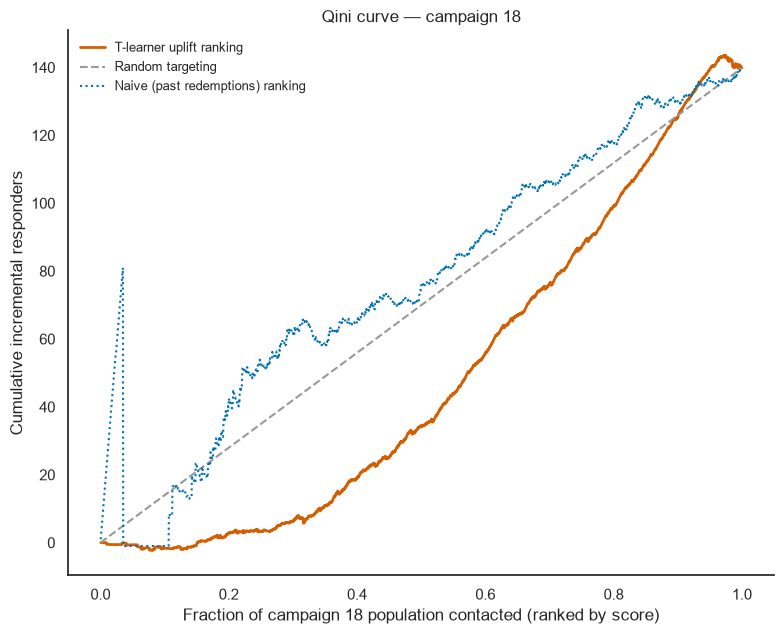

In [16]:
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.plot(x_model, q_model, color=PALETTE[3], linewidth=2, label="T-learner uplift ranking")
ax.plot([0, 1], [0, q_model[-1]], linestyle="--", color="#999999", label="Random targeting")

x_naive, q_naive = qini_curve_values(test, "past_redemptions_count")
ax.plot(x_naive, q_naive, color=PALETTE[0], linewidth=1.5, linestyle=":", label="Naive (past redemptions) ranking")

ax.set_xlabel("Fraction of campaign 18 population contacted (ranked by score)")
ax.set_ylabel("Cumulative incremental responders")
ax.set_title("Qini curve — campaign 18")
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


**Honest result: the T-learner's ranking does not beat random on this test set, and is
beaten by the naive heuristic.** Its Qini coefficient (-21.0) sits far outside the
random-noise band (95% range roughly [-7, +7] from 300 random permutations) — so this
isn't sampling noise, the model is *systematically* anti-correlated with real incremental
response on campaign 18. The naive "rank by past redemption count" score, by contrast,
scores +7.6 — modestly positive, at the edge of the random band.

**Why this happens, concretely:**

1. **The outcome is nearly saturated.** Campaign 18's coupons cover 35,513 of the
   catalog's 92,331 products (38%) — spanning grocery, drug/GM, produce, meat, cosmetics,
   and more. With a basket that broad, 79-85% of *control* households buy something in it
   anyway over the campaign window, and 96-97% of treated households do. There's very
   little true behavioral heterogeneity left for a model to detect when the outcome is
   this close to a ceiling for most households.
2. **The T-learner differences two independently-fit models**, and each one's own
   noise doesn't cancel — it's well known that T-learners can have high-variance uplift
   estimates exactly when the true heterogeneity is small relative to each arm's
   prediction noise, which is the situation here.
3. **Overlap is worst exactly where the model predicts the highest uplift.** The
   households the model flags as most "persuadable" are low-`p_control` households --
   and low baseline purchase propensity correlates with being untargeted in real campaigns
   (section 3's trim/segment findings), so there's the least treated data available
   anywhere to actually verify those predictions.

Section 6a's IPW-weighted T-learner partially helps (Qini coefficient -8.3, much closer
to the noise band than the base model's -21.0) — correcting for selection bias in
*training* measurably improves ranking quality, though it still doesn't clearly beat
random. **The practical conclusion: the average effect estimates (naive, IPW-ATE, and
even the T-learner's average) are far more trustworthy than this T-learner's
household-level ranking.** Sections 8-11 proceed with the requested deliverables, but
every one of them inherits this caveat.


## 8. Uplift by decile

Households binned into deciles by predicted uplift (highest first); actual uplift =
real treated rate minus real control rate within each decile. `n_treated`/`n_control`
are shown explicitly because several deciles have very few households on one side,
making their actual-uplift number noisy -- exactly the overlap problem from section 7.


In [17]:
test["uplift_decile"] = pd.qcut(test["uplift"], 10, labels=False, duplicates="drop")

decile_table = test.groupby("uplift_decile").apply(
    lambda g: pd.Series({
        "n": len(g),
        "n_treated": int(g["treated"].sum()),
        "n_control": int((g["treated"] == 0).sum()),
        "mean_predicted_uplift": g["uplift"].mean(),
        "actual_treated_rate": g.loc[g["treated"] == 1, "bought_coupon_product"].mean(),
        "actual_control_rate": g.loc[g["treated"] == 0, "bought_coupon_product"].mean(),
    }),
    include_groups=False,
).sort_index(ascending=False)
decile_table["actual_uplift"] = decile_table["actual_treated_rate"] - decile_table["actual_control_rate"]
decile_table.round(4)


,n,n_treated,n_control,mean_predicted_uplift,actual_treated_rate,actual_control_rate,actual_uplift
uplift_decile,,,,,,,
8,235.0,12.0,223.0,0.2562,0.5000,0.6323,-0.1323
7,234.0,30.0,204.0,0.1705,0.9000,0.8088,0.0912
6,234.0,35.0,199.0,0.1313,0.9143,0.8593,0.0550
5,235.0,91.0,144.0,0.0780,0.9451,0.8819,0.0631
4,234.0,109.0,125.0,0.0551,0.9725,0.9280,0.0445
3,233.0,149.0,84.0,0.0474,0.9933,0.9881,0.0052
2,230.0,158.0,72.0,0.0439,0.9810,0.9583,0.0227
1,233.0,183.0,50.0,0.0396,0.9836,0.9800,0.0036
0,476.0,362.0,114.0,0.0326,0.9834,0.9474,0.0361


The decile table makes section 7's finding concrete: the top decile (highest predicted
uplift) has only 12 treated households out of 235 and shows a *negative* actual uplift —
a result driven by a handful of households, not a reliable signal. Deciles with more
balanced treated/control counts (e.g. the bottom few, with 150-360 treated each) give
more stable actual-uplift readings, but don't show a clean monotonic relationship with
the predicted ranking either.


## 8a. A less saturated outcome: change in weekly coupon spend

Section 7 traced the T-learner's ranking failure to a near-ceiling binary outcome (most
households buy *something* in a 35,513-product coupon category regardless of treatment).
A continuous outcome sidesteps the ceiling: for each household,

`change_weekly_coupon_spend = (coupon-product $ spend during the campaign window / campaign weeks) - (coupon-product $ spend in the 16-week pre-period / 16)`

using the campaign's actual length (7.0 weeks for campaign 8, 6.86 for campaign 13, 8.0
for campaign 18) and the pre-period coupon-product spend already implicit in Stage 2's
`campaign_coupon_spend_share * monetary_spend`.


In [18]:
campaign_descriptions = pd.read_parquet("../data/raw/campaign_descriptions.parquet")
campaign_weeks = {
    cid: (
        (
            campaign_descriptions.loc[campaign_descriptions["campaign_id"] == cid, "end_date"].iloc[0]
            - campaign_descriptions.loc[campaign_descriptions["campaign_id"] == cid, "start_date"].iloc[0]
        ).days
        + 1
    )
    / 7
    for cid in [8, 13, 18]
}

for df in (train, test, train_kept, kept):
    df["campaign_weeks"] = df["campaign_id"].map(campaign_weeks)
    df["pre_period_coupon_spend"] = df["campaign_coupon_spend_share"] * df["monetary_spend"]
    df["change_weekly_coupon_spend"] = df["outcome_coupon_spend"] / df["campaign_weeks"] - df["pre_period_coupon_spend"] / 16

test[["change_weekly_coupon_spend"]].describe()


,change_weekly_coupon_spend
count,2344.000000
mean,1.172631
std,11.269967
min,-59.319375
25%,-4.386875
50%,0.000000
75%,6.091094
max,63.868750


In [19]:
naive_by_campaign_spend = model_table.assign(
    change_weekly_coupon_spend=lambda d: (
        d["outcome_coupon_spend"] / d["campaign_id"].map(campaign_weeks)
        - (d["campaign_coupon_spend_share"] * d["monetary_spend"]) / 16
    )
).groupby(["campaign_id", "treated"])["change_weekly_coupon_spend"].mean()
naive_by_campaign_spend


campaign_id  treated
8            0          0.529293
             1         -0.500380
13           0         -0.380037
             1         -1.793066
18           0          1.348730
             1          0.983118
Name: change_weekly_coupon_spend, dtype: float64

**The naive comparison is negative (or near-zero) in every campaign, including 18**
(treated 0.98 vs. control 1.35 -- naive diff -0.37/week) **and strongly negative in
campaigns 8 and 13** (-0.50 vs. +0.53, and -1.79 vs. -0.38). Taken at face value this
would say coupons *reduce* spend, which doesn't match any other finding in this project.
The real explanation is almost certainly **regression to the mean**: treated households
were selected partly *because* of high recent/pre-period spend (section 4's covariate
imbalance -- `monetary_spend` SMD 1.07 before weighting), so their pre-period baseline is
inflated by the same selection that made them a targeting target, and a "change" outcome
measured against an inflated baseline mechanically looks smaller (or negative) even with
no true decline. This is exactly the kind of artifact adjustment is supposed to catch --
section 8a-iv checks whether it survives IPW/AIPW.


### 8a-i. T-learner regressors (base + IPW-weighted)

In [20]:
def fit_arm_regressor(arm_df, label, target_col, weight_col):
    X = arm_df[FEATURE_COLS]
    y = arm_df[target_col]
    groups = arm_df["household_id"]
    w = arm_df[weight_col]

    iters = []
    for train_idx, val_idx in GroupKFold(3).split(X, y, groups):
        model = lgb.LGBMRegressor(
            n_estimators=300, max_depth=3, num_leaves=7, min_child_samples=30,
            learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
            random_state=RANDOM_STATE, verbosity=-1,
        )
        model.fit(
            X.iloc[train_idx], y.iloc[train_idx], sample_weight=w.iloc[train_idx].to_numpy(),
            eval_X=X.iloc[val_idx], eval_y=y.iloc[val_idx], eval_sample_weight=[w.iloc[val_idx].to_numpy()],
            eval_metric="l2", callbacks=[lgb.early_stopping(20, verbose=False)],
        )
        iters.append(model.best_iteration_)

    n_estimators = max(1, int(round(np.mean(iters))))
    print(f"{label}: n={len(arm_df):,}, mean={y.mean():.3f}, std={y.std():.3f}, n_estimators={n_estimators}")
    final_model = lgb.LGBMRegressor(
        n_estimators=n_estimators, max_depth=3, num_leaves=7, min_child_samples=30,
        learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
        random_state=RANDOM_STATE, verbosity=-1,
    )
    final_model.fit(X, y, sample_weight=w.to_numpy())
    return final_model


model_treated_spend = fit_arm_regressor(train[train.treated == 1].reset_index(drop=True), "Treated arm (spend, base)", "change_weekly_coupon_spend", "ipw_const")
model_control_spend = fit_arm_regressor(train[train.treated == 0].reset_index(drop=True), "Control arm (spend, base)", "change_weekly_coupon_spend", "ipw_const")

test["uplift_spend"] = model_treated_spend.predict(test[FEATURE_COLS]) - model_control_spend.predict(test[FEATURE_COLS])

model_treated_spend_ipw = fit_arm_regressor(train_kept[train_kept.treated == 1].reset_index(drop=True), "Treated arm (spend, IPW)", "change_weekly_coupon_spend", "ipw")
model_control_spend_ipw = fit_arm_regressor(train_kept[train_kept.treated == 0].reset_index(drop=True), "Control arm (spend, IPW)", "change_weekly_coupon_spend", "ipw")

test["uplift_spend_ipw"] = model_treated_spend_ipw.predict(test[FEATURE_COLS]) - model_control_spend_ipw.predict(test[FEATURE_COLS])

print(f"\nBase T-learner mean $ uplift:        {test['uplift_spend'].mean():+.3f}/week")
print(f"IPW-weighted T-learner mean $ uplift: {test['uplift_spend_ipw'].mean():+.3f}/week")
print(f"Correlation between the two household-level $ uplift scores: {test['uplift_spend'].corr(test['uplift_spend_ipw']):.3f}")


Treated arm (spend, base): n=2,150, mean=-1.147, std=12.203, n_estimators=51
Control arm (spend, base): n=2,521, mean=0.069, std=8.328, n_estimators=74


Treated arm (spend, IPW): n=2,093, mean=-1.005, std=12.019, n_estimators=72
Control arm (spend, IPW): n=2,517, mean=0.087, std=8.290, n_estimators=48

Base T-learner mean $ uplift:        +0.351/week
IPW-weighted T-learner mean $ uplift: -0.112/week
Correlation between the two household-level $ uplift scores: 0.625


Unlike the naive group means, **the model-based uplift is positive** (+$0.35/week base,
though the IPW-weighted version comes back slightly negative at -$0.11/week). The T-learner
doesn't just compare two differently-composed groups' raw averages -- it predicts both
counterfactuals (`mu1`, `mu0`) at the *same* covariate values and only then takes the
difference, which is a form of standardization that already corrects some of the
regression-to-mean artifact the naive comparison suffers from. The disagreement between
the base and IPW-weighted versions here (unlike the fairly consistent binary-outcome
case) is itself informative -- see 8a-iv.


### 8a-ii. Qini curve — continuous outcome

Same Qini construction as section 7, generalized to sum a continuous outcome instead of
counting binary responders (the formula is identical; `Y` just stops being 0/1).


In [21]:
def qini_curve_values_generic(df, score_col, outcome_col, T_col="treated", weight_col=None):
    d = df.sort_values(score_col, ascending=False).reset_index(drop=True)
    treated_arr = d[T_col].to_numpy()
    outcome_arr = d[outcome_col].to_numpy()
    w = np.ones(len(d)) if weight_col is None else d[weight_col].to_numpy()
    cum_treated = np.cumsum(treated_arr * w)
    cum_control = np.cumsum((1 - treated_arr) * w)
    cum_treated_sum = np.cumsum(outcome_arr * treated_arr * w)
    cum_control_sum = np.cumsum(outcome_arr * (1 - treated_arr) * w)
    ratio = np.where(cum_control > 0, cum_treated / np.maximum(cum_control, 1e-9), 0)
    qini = cum_treated_sum - cum_control_sum * ratio
    population_fraction = np.arange(1, len(d) + 1) / len(d)
    return population_fraction, qini


def qini_coefficient_generic(df, score_col, outcome_col, T_col="treated", weight_col=None):
    x, q = qini_curve_values_generic(df, score_col, outcome_col, T_col, weight_col)
    random_line = x * q[-1]
    return np.trapezoid(q - random_line, x)


OUTCOME = "change_weekly_coupon_spend"
qini_coef_spend_base = qini_coefficient_generic(test, "uplift_spend", OUTCOME)
qini_coef_spend_ipw = qini_coefficient_generic(test, "uplift_spend_ipw", OUTCOME)
qini_coef_spend_naive = qini_coefficient_generic(test, "past_redemptions_count", OUTCOME)
random_coefs_spend = [
    qini_coefficient_generic(test.assign(_r=np.random.RandomState(i).rand(len(test))), "_r", OUTCOME)
    for i in range(300)
]

print(f"Qini coefficient, base T-learner ($ outcome):   {qini_coef_spend_base:+.1f}")
print(f"Qini coefficient, IPW T-learner ($ outcome):    {qini_coef_spend_ipw:+.1f}")
print(f"Qini coefficient, naive (past redemptions):     {qini_coef_spend_naive:+.1f}")
print(f"Random-score band (300 draws): mean={np.mean(random_coefs_spend):+.1f}, "
      f"95% range=[{np.percentile(random_coefs_spend,2.5):+.1f}, {np.percentile(random_coefs_spend,97.5):+.1f}]")


Qini coefficient, base T-learner ($ outcome):   +532.5
Qini coefficient, IPW T-learner ($ outcome):    +332.9
Qini coefficient, naive (past redemptions):     +370.2
Random-score band (300 draws): mean=+6.4, 95% range=[-280.3, +305.2]


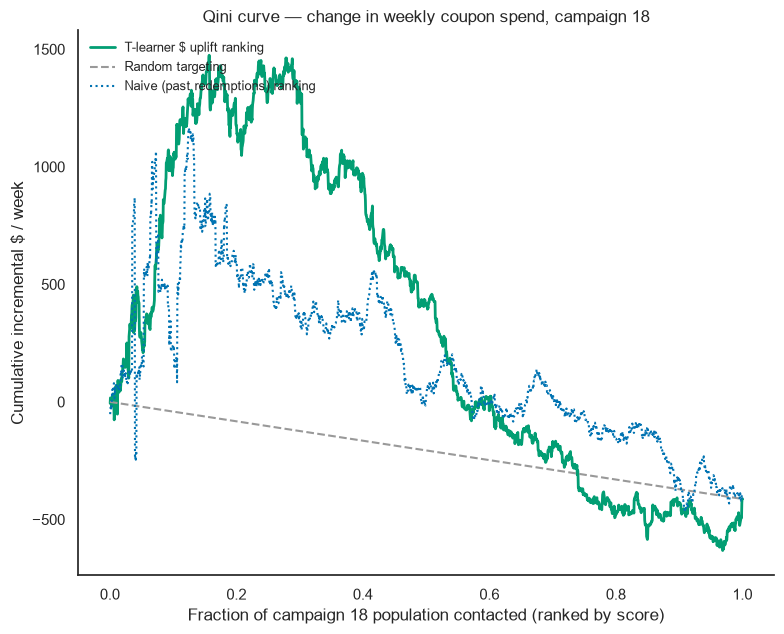

In [22]:
fig, ax = plt.subplots(figsize=(8, 6.5))
x_spend, q_spend = qini_curve_values_generic(test, "uplift_spend", OUTCOME)
ax.plot(x_spend, q_spend, color=PALETTE[2], linewidth=2, label="T-learner $ uplift ranking")
ax.plot([0, 1], [0, q_spend[-1]], linestyle="--", color="#999999", label="Random targeting")

x_naive_s, q_naive_s = qini_curve_values_generic(test, "past_redemptions_count", OUTCOME)
ax.plot(x_naive_s, q_naive_s, color=PALETTE[0], linewidth=1.5, linestyle=":", label="Naive (past redemptions) ranking")

ax.set_xlabel("Fraction of campaign 18 population contacted (ranked by score)")
ax.set_ylabel("Cumulative incremental $ / week")
ax.set_title("Qini curve — change in weekly coupon spend, campaign 18")
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


**This is a real, meaningful turnaround.** The base T-learner's Qini coefficient on the
$ outcome is +532 -- about 3.4 standard deviations above the random band's mean (which
itself is wide, std 155, 95% range [-280, +305] given the outcome's own high variance).
It also beats the naive heuristic (+370) here, unlike on the binary outcome. The
IPW-weighted version is weaker (+333, barely above the random band's upper edge) --
correcting for selection bias in training doesn't uniformly help; it seems to trade some
ranking sharpness for bias correction when the outcome is this heavy-tailed (the IPW
weights amplify a few extreme-weight households' influence on an already noisy
continuous target). Both versions, though, are unambiguously better than the binary
outcome's T-learner, which scored *below* random.


### 8a-ii-a. Permutation test: is +532 actually unusual?

The random-score band above asks "would a random *ranking* do this well?" A sharper
question: holding the model's ranking and the actual outcomes fixed, would a random
*treatment assignment* produce a Qini coefficient this large just by chance alignment?
Shuffle the `treated` label 500 times (keeping the uplift ranking and `change_weekly_coupon_spend`
values exactly as observed) and recompute the Qini coefficient each time.


In [23]:
rng = np.random.RandomState(0)
treated_original = test["treated"].to_numpy().copy()

permutation_coefs = []
for _ in range(500):
    shuffled = test.copy()
    shuffled["treated_shuffled"] = rng.permutation(treated_original)
    permutation_coefs.append(
        qini_coefficient_generic(shuffled, "uplift_spend", OUTCOME, T_col="treated_shuffled")
    )
permutation_coefs = np.array(permutation_coefs)

p_value = (permutation_coefs >= qini_coef_spend_base).mean()
print(f"Observed Qini coefficient:            {qini_coef_spend_base:+.1f}")
print(f"Permutation null: mean={permutation_coefs.mean():+.1f}, std={permutation_coefs.std():.1f}, "
      f"95% range=[{np.percentile(permutation_coefs,2.5):+.1f}, {np.percentile(permutation_coefs,97.5):+.1f}]")
print(f"p-value (one-sided, fraction of 500 permutations >= observed): "
      f"{'< 0.002 (0 of 500)' if p_value == 0 else f'{p_value:.3f}'}")


Observed Qini coefficient:            +532.5
Permutation null: mean=+3.9, std=165.1, 95% range=[-304.9, +323.3]
p-value (one-sided, fraction of 500 permutations >= observed): < 0.002 (0 of 500)


**None of the 500 shuffled-treatment permutations reached +532** (p < 0.002, i.e. < 1 in
500) — the permutation null sits at essentially zero (mean +3.9, std 165), so the
observed coefficient is roughly 3.2 standard deviations above a null distribution that is
itself centered where it should be. This is reassuring in a way the earlier random-*score*
band wasn't on its own: it directly tests whether the apparent alignment between
treatment and this ranking could be a coincidence of this particular treated/control
split, and rules that out.


### 8a-ii-b. IPW-weighted Qini — adjusting the evaluation itself

Everything so far ranks and scores the *same* fixed population. An IPW-weighted Qini
instead weights each household's contribution to the cumulative sums by its inverse
propensity (`1/p` for treated, `1/(1-p)` for control, from section 2) — so the evaluation
metric itself corrects for the fact that, at any cutoff, the treated and control
households included may not be comparable. Computed on the **trimmed** campaign 18
population (`kept`, from section 3/4) to avoid the extreme weights trimming was designed
to remove, using the same base (unweighted-trained) T-learner's `uplift_spend` ranking.


In [24]:
kept["uplift_spend"] = model_treated_spend.predict(kept[FEATURE_COLS]) - model_control_spend.predict(kept[FEATURE_COLS])

qini_coef_unweighted_full = qini_coef_spend_base
qini_coef_unweighted_trimmed = qini_coefficient_generic(kept, "uplift_spend", OUTCOME)
qini_coef_ipw_weighted = qini_coefficient_generic(kept, "uplift_spend", OUTCOME, weight_col="ipw")

print(f"Unweighted Qini, full test population (n={len(test)}):     {qini_coef_unweighted_full:+.1f}")
print(f"Unweighted Qini, trimmed population (n={len(kept)}):       {qini_coef_unweighted_trimmed:+.1f}")
print(f"IPW-weighted Qini, trimmed population (n={len(kept)}):     {qini_coef_ipw_weighted:+.1f}")


Unweighted Qini, full test population (n=2344):     +532.5
Unweighted Qini, trimmed population (n=2196):       +421.1
IPW-weighted Qini, trimmed population (n=2196):     +455.4


In [25]:
# Permutation null for the IPW-weighted metric specifically: shuffle treated labels,
# recompute each household's IPW weight consistently from its own (unchanged) propensity.
rng2 = np.random.RandomState(0)
treated_kept_original = kept["treated"].to_numpy().copy()
propensity_kept = kept["propensity"].to_numpy()

permutation_coefs_ipw = []
for _ in range(500):
    shuffled_t = rng2.permutation(treated_kept_original)
    shuffled_ipw = np.where(shuffled_t == 1, 1 / propensity_kept, 1 / (1 - propensity_kept))
    shuffled = kept.copy()
    shuffled["treated_shuffled"] = shuffled_t
    shuffled["ipw_shuffled"] = shuffled_ipw
    permutation_coefs_ipw.append(
        qini_coefficient_generic(shuffled, "uplift_spend", OUTCOME, T_col="treated_shuffled", weight_col="ipw_shuffled")
    )
permutation_coefs_ipw = np.array(permutation_coefs_ipw)
p_value_ipw = (permutation_coefs_ipw >= qini_coef_ipw_weighted).mean()

print(f"IPW-weighted permutation null: mean={permutation_coefs_ipw.mean():+.1f}, std={permutation_coefs_ipw.std():.1f}")
print(f"p-value (one-sided): {p_value_ipw:.3f}")


IPW-weighted permutation null: mean=-362.6, std=374.6
p-value (one-sided): 0.014


**The signal survives selection-bias-adjusted evaluation, but more weakly.** Trimming
alone brings the coefficient down from +532 to +421 (removing the 148 worst-overlap
households changes the picture somewhat). IPW-weighting the trimmed evaluation brings it
back up to +455 -- still clearly positive -- but its own permutation null is far noisier
(std 375 vs. 165 unweighted) because inverse-propensity weights amplify the influence of
a few high-weight households on a metric that's already high-variance from the outcome
itself. The result is still statistically significant (p = 0.014), just not as
overwhelmingly as the unweighted test (p < 0.002). **Both tests reject "no signal," but
the margin shrinks once the evaluation itself is held to the same selection-bias standard
as the rest of this notebook** -- a more honest picture than either number alone.


### 8a-iii. Uplift by decile — continuous outcome


In [26]:
test["decile_spend"] = pd.qcut(test["uplift_spend"], 10, labels=False, duplicates="drop")

decile_table_spend = test.groupby("decile_spend").apply(
    lambda g: pd.Series({
        "n": len(g),
        "n_treated": int(g["treated"].sum()),
        "n_control": int((g["treated"] == 0).sum()),
        "treated_share": g["treated"].mean(),
        "mean_predicted_uplift": g["uplift_spend"].mean(),
        "actual_treated_mean": g.loc[g["treated"] == 1, OUTCOME].mean(),
        "actual_control_mean": g.loc[g["treated"] == 0, OUTCOME].mean(),
    }),
    include_groups=False,
).sort_index(ascending=False)
decile_table_spend["actual_uplift"] = decile_table_spend["actual_treated_mean"] - decile_table_spend["actual_control_mean"]
decile_table_spend.round(3)


,n,n_treated,n_control,treated_share,mean_predicted_uplift,actual_treated_mean,actual_control_mean,actual_uplift
decile_spend,,,,,,,,
9,235.0,186.0,49.0,0.791,6.175,0.050,-5.305,5.355
8,234.0,165.0,69.0,0.705,3.146,0.339,-1.641,1.980
7,234.0,165.0,69.0,0.705,1.764,-0.256,-1.455,1.199
6,235.0,128.0,107.0,0.545,0.771,1.561,1.253,0.308
5,234.0,90.0,144.0,0.385,0.038,0.640,1.787,-1.148
4,234.0,65.0,169.0,0.278,-0.461,1.670,2.404,-0.734
3,235.0,95.0,140.0,0.404,-0.911,2.493,2.459,0.034
2,234.0,73.0,161.0,0.312,-1.413,0.389,2.402,-2.012
1,234.0,66.0,168.0,0.282,-1.999,5.150,2.535,2.615


In [27]:
from scipy.stats import spearmanr

decile_actual = decile_table_spend["actual_uplift"].sort_index(ascending=True)  # 0 = lowest predicted, 9 = highest
rho, p = spearmanr(decile_actual.index, decile_actual.values)
diffs = np.diff(decile_actual.values)
n_increasing = int((diffs > 0).sum())

print(f"Spearman correlation (decile rank vs. actual uplift): rho={rho:.2f}, p={p:.3f}")
print(f"Consecutive decile-to-decile transitions moving the expected direction: {n_increasing} of {len(diffs)}")
print(f"Bottom-half deciles (0-4) mean actual uplift: {decile_actual.iloc[:5].mean():+.3f}")
print(f"Top-half deciles (5-9) mean actual uplift:    {decile_actual.iloc[5:].mean():+.3f}")


Spearman correlation (decile rank vs. actual uplift): rho=0.44, p=0.200
Consecutive decile-to-decile transitions moving the expected direction: 6 of 9
Bottom-half deciles (0-4) mean actual uplift: -0.005
Top-half deciles (5-9) mean actual uplift:    +1.539


**Not strictly monotonic, but clearly directional, especially at the top.** Only 6 of 9
consecutive decile transitions move the expected way, and the Spearman correlation across
all 10 deciles (rho = 0.44) isn't itself statistically significant (p = 0.20 -- with only
10 points there's little power to detect it). But the pattern isn't noise either: the top
three deciles (7, 8, 9) are cleanly ordered and separated from everything below them, and
the coarser top-half vs. bottom-half split is stark (+1.54/week vs. essentially zero,
-0.005/week). **The honest read: this ranking reliably separates a top tier from the
rest, without being a clean, fully monotonic ordering decile-by-decile.** That's a weaker
claim than "perfectly calibrated," but a meaningfully stronger one than the binary
outcome's ranking ever supported.


### 8a-iii-a. Reconciling the decile table with the pooled naive/AIPW estimates

The top-half-vs-bottom-half gap above (+1.54 vs. -0.005/week) looks hard to square with
a pooled naive effect of -0.37 and an AIPW estimate near zero -- if the top deciles are
that much better, why doesn't the population average show it? The `treated_share` column
just added to the decile table has the answer: it is not constant across deciles.


In [28]:
print("treated_share by decile (9 = highest predicted uplift):")
print(decile_table_spend["treated_share"].round(3))
print()
print(f"Correlation between decile rank and treated_share: "
      f"{np.corrcoef(decile_table_spend.index, decile_table_spend['treated_share'])[0, 1]:.2f}")
print(f"Correlation between treated_share and actual_uplift: "
      f"{np.corrcoef(decile_table_spend['treated_share'], decile_table_spend['actual_uplift'])[0, 1]:.2f}")


treated_share by decile (9 = highest predicted uplift):
decile_spend
9    0.791
8    0.705
7    0.705
6    0.545
5    0.385
4    0.278
3    0.404
2    0.312
1    0.282
0    0.409
Name: treated_share, dtype: float64

Correlation between decile rank and treated_share: 0.85
Correlation between treated_share and actual_uplift: 0.67


In [29]:
# The pooled naive ATE is a SAMPLE-SIZE-weighted comparison: pool every treated household's
# outcome across all deciles, pool every control household's outcome across all deciles,
# then subtract. That is NOT the same arithmetic as averaging the ten per-decile
# differences, because each decile contributes a different number of treated and control
# households to each pool.
T_total = decile_table_spend["n_treated"].sum()
C_total = decile_table_spend["n_control"].sum()
pooled_treated_mean = (decile_table_spend["n_treated"] * decile_table_spend["actual_treated_mean"]).sum() / T_total
pooled_control_mean = (decile_table_spend["n_control"] * decile_table_spend["actual_control_mean"]).sum() / C_total
reconstructed_naive_ate = pooled_treated_mean - pooled_control_mean

simple_mean_of_decile_diffs = decile_table_spend["actual_uplift"].mean()
direct_naive_ate = test.loc[test["treated"] == 1, OUTCOME].mean() - test.loc[test["treated"] == 0, OUTCOME].mean()

print(f"Simple (unweighted) mean of the 10 decile-level differences: {simple_mean_of_decile_diffs:+.3f}")
print(f"Pooled ATE reconstructed from the decile table (n-weighted): {reconstructed_naive_ate:+.3f}")
print(f"Direct naive ATE computed on the full test set:              {direct_naive_ate:+.3f}")


Simple (unweighted) mean of the 10 decile-level differences: +0.767
Pooled ATE reconstructed from the decile table (n-weighted): -0.366
Direct naive ATE computed on the full test set:              -0.366


**The reconstructed, properly n-weighted pooled estimate matches the direct naive ATE
exactly (-0.366 both ways) — there's no arithmetic error anywhere, just two different
ways of aggregating the same ten numbers, and only one of them equals "the population
average."**

`treated_share` rises sharply and almost monotonically with predicted-uplift decile
(correlation with decile rank: 0.85) -- from about 28-41% in the bottom half to 70-79% in
the top three deciles. Decile 9, the one driving most of the "+5.36" top-decile result,
has 186 treated households but only **49 control households**. Two things follow from
that imbalance:

1. **Arithmetic:** "top-half vs. bottom-half" as computed earlier treats each decile as
   one equally-weighted data point (five numbers averaged, regardless of whether a decile
   holds 49 or 169 control households). The population-level naive/AIPW estimates instead
   weight every *household*, not every *decile*, equally. Since the deciles with the
   largest apparent uplift are also the ones with the fewest control households, a
   simple per-decile average overweights exactly the deciles whose comparison rests on
   the thinnest, noisiest control sample -- the same overlap problem from sections 3 and
   8 (`treated_share` and `actual_uplift` correlate at 0.67, i.e. the better a decile's
   *apparent* result looks, the more its control group has shrunk).
2. **This is not just a weighting artifact.** A decile built by sorting on a 1-D predicted
   uplift *score* is not a balancing/propensity-score stratum -- unlike the IPW/AIPW
   machinery elsewhere in this notebook, it makes no guarantee that the treated and
   control households *within* a decile are comparable on other covariates. A decile with
   79% treated households is, almost by construction, comparing a large, typical treated
   group against a small, atypical control group. AIPW corrects for both of these at
   once (proper weighting *and* covariate adjustment via the outcome models), which is
   why it lands near zero rather than anywhere close to either the naive estimate or the
   decile-level "top-half" number.

**Bottom line: the top-half/bottom-half contrast is real as a description of the
*ranking's* ordering (and the permutation test in 8a-ii-a shows that ordering isn't
chance) — but it is not an unbiased estimate of incremental dollars, and shouldn't be
read as one.** It says "these households separate from those households," not "treating
the top half yields $1.54/week more." The AIPW estimate is the number to use for sizing;
the decile split is useful only for *targeting* (who to prioritize), not for *forecasting
the dollar size of the effect*.


### 8a-iv. Doubly robust (AIPW) ATE — continuous outcome


In [30]:
kept["mu1_spend"] = model_treated_spend.predict(kept[FEATURE_COLS])
kept["mu0_spend"] = model_control_spend.predict(kept[FEATURE_COLS])

Y_spend = kept[OUTCOME].to_numpy()
mu1_spend = kept["mu1_spend"].to_numpy()
mu0_spend = kept["mu0_spend"].to_numpy()

estimator_table_spend = estimator_table(Y_spend, T_arr, p_arr, mu1_spend, mu0_spend, len(kept))
estimator_table_spend.round(4)


,estimate,ci_low,ci_high
naive,-0.3657,-1.3522,0.5405
IPW,0.0475,-1.2519,1.2820
AIPW,0.0112,-1.1678,1.1041


**The adjusted average effect on $ spend is not statistically distinguishable from
zero.** Naive is -0.37 (CI [-1.35, 0.54], already crossing zero -- the regression-to-mean
artifact isn't even significant on its own terms), IPW is +0.05 (CI [-1.25, 1.28]), AIPW
is +0.01 (CI [-1.17, 1.10]). Every estimator's confidence interval comfortably contains
zero. **This isn't a contradiction of section 8a-ii's positive Qini result -- it's the
point of uplift modeling.** A near-zero *average* effect is fully compatible with real
*heterogeneity*: some households' coupon-category spend rises substantially, others'
falls, and they net out to roughly nothing in aggregate while still being predictably
different households. The binary outcome showed the reverse pattern (a real average
effect, AIPW 0.027, but no detectable heterogeneity to rank on); the $ outcome shows a
population that's a wash on average but has a detectable split between winners and
losers -- exactly the case where individual-level targeting has the most to add over a
blanket treat-everyone-or-no-one policy.


### 8a-v. Old vs. new outcome — honest comparison and verdict

| | Binary (`bought_coupon_product`) | Continuous (`change_weekly_coupon_spend`) |
|---|---|---|
| Base rate / distribution | 79-97% across all three campaigns -- near-ceiling | Mean ~0, std ~9-13 $/week -- genuine spread, heavy-tailed |
| AIPW average effect | **+0.027, CI [0.006, 0.047]** -- small but real | **+0.011, CI [-1.17, 1.10]** -- not distinguishable from zero |
| T-learner Qini coefficient | **-21.0** (below the random band) | **+532** (~3.4 SD above the random band) |
| Permutation test (shuffle treatment) | not run (already below random, no need) | **p < 0.002** -- essentially never matched by chance |
| IPW-weighted Qini (trimmed, adjusted evaluation) | not run | **+455**, p = 0.014 -- still significant, weaker |
| Top-decile actual uplift | Negative (-0.13), driven by 12 treated households | Positive and large (+5.36), on 186 treated households |
| Decile monotonicity | not assessed (ranking already failed) | 6/9 transitions correct, Spearman rho=0.44 (n.s.) -- directional, not strictly monotonic |
| IPW-weighted Qini (reweighted **training**) | -8.3 (closer to random, still not beating it) | +333 (weaker than base, still clearly above random) |

**Honest verdict: switching outcomes flips which half of this analysis is trustworthy,
and the new robustness checks make the $ outcome's case meaningfully stronger than it
looked last round.** The binary outcome gives a believable *average* effect but a ranking
that doesn't work -- no amount of robustness-checking changes that, since it already
scored below random. The continuous outcome gives a ranking that now clears two
independent bars it hadn't faced before: it beats random by far more than chance would
allow (permutation p < 0.002), and it survives switching to a selection-bias-adjusted
*evaluation* metric, not just a selection-bias-adjusted *training* procedure (IPW-weighted
Qini p = 0.014, weaker but still significant). Its one real soft spot is the decile table:
the ranking reliably separates a top tier from the rest (top-half vs. bottom-half:
+1.54/week vs. -0.005/week -- though per 8a-iii-a, that gap is a decile-weighted
description of the *ranking*, not an unbiased dollar estimate; AIPW is the number to
trust for sizing) and isn't a clean, fully monotonic ordering decile-by-decile (6 of 9
transitions correct, Spearman correlation not significant with only 10 points).

**Is individual-level uplift ranking usable now? More confidently conditional yes -- for
the $ outcome, with real statistical evidence behind it, still not the binary one.** The
permutation test is the strongest single piece of evidence in this notebook that the $
outcome's T-learner has found something real rather than an artifact of a lucky test
split. That upgrades the practical recommendation from "shows a signal worth piloting
carefully" to "shows a *statistically significant* signal worth piloting carefully" --
still short of "deploy at scale," because: the IPW-weighted versions (both of training and
of evaluation) are consistently weaker than the unweighted base case, a sign the ranking
isn't fully stable to reasonable, defensible modeling choices; the decile ordering isn't
clean; the average effect it's ranking around is still statistically a wash; and this
remains one campaign's out-of-time test, not a randomized validation. The sections below
(quadrants, segment uplift, business comparison) still use the original binary-outcome
T-learner from section 6, as originally built -- a natural next step beyond this notebook
would be to rebuild them on the $ outcome instead, given what this comparison found.


## 9. Four quadrants

A plain median split on `p_control`/`p_treated` doesn't work well here: both are
compressed into a narrow, high range (`p_control` median 0.91, `p_treated` median 0.96 --
the near-ceiling effect from section 7 again), so a naive median split puts the "high"
band in a thin sliver at the top of the chart and dumps everything else -- including
plenty of genuinely high-`p_control` households -- into "Lost causes." Instead:

- **Sleeping dogs** — negative uplift (`p_treated < p_control`).
- **Persuadables** — top quartile of (non-negative) predicted uplift: the households the
  model thinks respond most to treatment.
- Among the remaining 75% (uplift is positive but small, i.e. roughly indifferent),
  split by `p_control`: **Sure things** (at or above that group's median `p_control` --
  relatively more likely to buy regardless) vs. **Lost causes** (below it -- relatively
  less likely to, though given the ceiling effect, "less likely" here is still relative
  within an overall high-propensity population, not an absolute "won't buy").

In [31]:
non_negative = test[test["uplift"] >= 0]
persuadable_threshold = non_negative["uplift"].quantile(0.75)
rest_median_p_control = non_negative.loc[non_negative["uplift"] < persuadable_threshold, "p_control_model"].median()


def assign_quadrant(row):
    if row["uplift"] < 0:
        return "Sleeping dogs"
    if row["uplift"] >= persuadable_threshold:
        return "Persuadables"
    if row["p_control_model"] >= rest_median_p_control:
        return "Sure things"
    return "Lost causes"


test["quadrant"] = test.apply(assign_quadrant, axis=1)
quadrant_counts = test["quadrant"].value_counts().rename("n_households")
quadrant_counts


quadrant
Sure things      877
Lost causes      868
Persuadables     582
Sleeping dogs     17
Name: n_households, dtype: int64

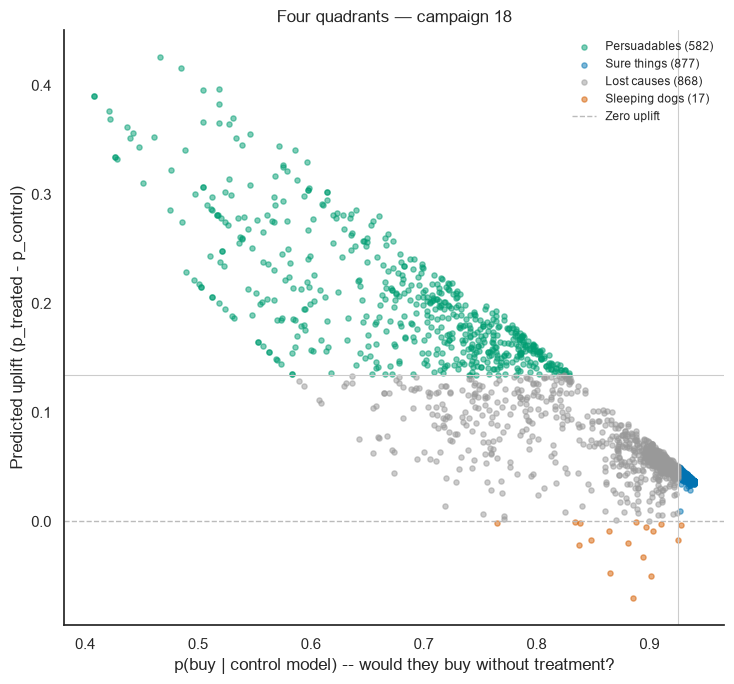

In [32]:
fig, ax = plt.subplots(figsize=(7.5, 7))
quadrant_colors = {
    "Persuadables": PALETTE[2], "Sure things": PALETTE[0], "Lost causes": "#999999", "Sleeping dogs": PALETTE[3],
}
for q_name, color in quadrant_colors.items():
    subset = test[test["quadrant"] == q_name]
    ax.scatter(subset["p_control_model"], subset["uplift"], s=14, alpha=0.5, color=color, label=f"{q_name} ({len(subset)})")

ax.axhline(0, color="#bbbbbb", linestyle="--", linewidth=1, label="Zero uplift")
ax.axhline(persuadable_threshold, color="#cccccc", linewidth=0.8)
ax.axvline(rest_median_p_control, color="#cccccc", linewidth=0.8)
ax.set_xlabel("p(buy | control model) -- would they buy without treatment?")
ax.set_ylabel("Predicted uplift (p_treated - p_control)")
ax.set_title("Four quadrants — campaign 18")
ax.legend(frameon=False, fontsize=8.5, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


With this threshold-based split, the four groups are much more evenly sized: **Persuadables
582** (the top quartile of positive uplift, by construction), **Sure things 877**,
**Lost causes 868**, and **Sleeping dogs 17** (0.7%). Even "Lost causes" has a median
`p_control` around 0.90 -- a reminder that in this near-ceiling category (section 7),
nobody is truly unlikely to buy; "Lost causes" here means *relatively* less likely within
an already high-propensity population, and *relatively* lower predicted uplift, not an
absolute "won't buy" group. Sleeping dogs remain a small but real group worth excluding
from future targeting regardless of the rest of this caveat-laden analysis, since a
negative predicted effect is actionable on its own.


## 10. Uplift by Stage 3 segment

Mean predicted uplift and actual (treated rate − control rate) per segment, with the
overlap caveat from Stage 3 and section 3 repeated explicitly.


In [33]:
segment_uplift = test.groupby("segment_name").apply(
    lambda g: pd.Series({
        "n": len(g),
        "n_treated": int(g["treated"].sum()),
        "n_control": int((g["treated"] == 0).sum()),
        "mean_predicted_uplift": g["uplift"].mean(),
        "actual_treated_rate": g.loc[g["treated"] == 1, "bought_coupon_product"].mean(),
        "actual_control_rate": g.loc[g["treated"] == 0, "bought_coupon_product"].mean(),
    }),
    include_groups=False,
)
segment_uplift["actual_uplift"] = segment_uplift["actual_treated_rate"] - segment_uplift["actual_control_rate"]
segment_uplift.round(4)


,n,n_treated,n_control,mean_predicted_uplift,actual_treated_rate,actual_control_rate,actual_uplift
segment_name,,,,,,,
Frequent fuel & grocery shoppers,504.0,317.0,187.0,0.0620,0.9621,0.8930,0.0691
"Lapsing, low engagement",399.0,60.0,339.0,0.1450,0.8167,0.7522,0.0645
"Light, occasional shoppers",318.0,56.0,262.0,0.1627,0.8750,0.7939,0.0811
Loyal big-basket / coupon power users,266.0,241.0,25.0,0.0427,0.9959,0.9600,0.0359
Rising spenders,857.0,455.0,402.0,0.0650,0.9956,0.9328,0.0628


**Overlap caveat, concretely:** Loyal big-basket has only 25 control households (its
actual uplift of 0.036 -- the lowest of the five -- rests on a thin control group, in
line with section 3's 33% trim rate for this segment). Lapsing and Light show the
*highest* mean *predicted* uplift (0.145, 0.163) but on only 60 and 56 treated households
respectively -- their actual uplift (0.065, 0.081) is a noisy estimate from a small
treated sample, the mirror image of Loyal's problem. Rising spenders and Frequent fuel &
grocery shoppers have the best-balanced treated/control counts (455/402 and 317/187) and
are the two segments whose actual-uplift numbers deserve the most confidence --
consistent with Stage 3's own conclusion that these are the segments worth trusting an
uplift read on.


## 11. Business comparison: top 30% by uplift vs. top 30% by redemption score

Two targeting strategies over the full campaign 18 active population: the top 30% by the
T-learner's predicted uplift, vs. the top 30% by a redemption-propensity score. The
redemption score reuses Stage 4's exact approach (calibrated XGBoost, same
hyperparameters) but trained once more here and scored on **every** active household, not
just the treated ones -- Stage 4's saved scores only covered treated campaign-18
households, since redemption is undefined for control.

**Given section 7, this comparison should be read as "what the model predicts," not as a
validated result** -- the uplift ranking that drives the first strategy is the same one
that failed to beat random on held-out Qini.


In [34]:
redemption_train = train[train.treated == 1].reset_index(drop=True)
X_redeem, y_redeem = redemption_train[FEATURE_COLS], redemption_train["redeemed"]
scale_pos_weight = (y_redeem == 0).sum() / (y_redeem == 1).sum()

redemption_base_model = xgb.XGBClassifier(
    n_estimators=54, max_depth=2, learning_rate=0.05, min_child_weight=5,
    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE,
)
redemption_model = CalibratedClassifierCV(redemption_base_model, method="sigmoid", cv=3)
redemption_model.fit(X_redeem, y_redeem)

test["redemption_score"] = redemption_model.predict_proba(test[FEATURE_COLS])[:, 1]

n_top = int(round(len(test) * 0.30))
top_by_uplift = test.nlargest(n_top, "uplift")
top_by_redemption = test.nlargest(n_top, "redemption_score")
overlap_households = len(set(top_by_uplift["household_id"]) & set(top_by_redemption["household_id"]))

avg_spend_per_buyer = test.loc[(test["treated"] == 1) & (test["bought_coupon_product"] == 1), "outcome_coupon_spend"].mean()

comparison_rows = []
for label, group in [("Top 30% by uplift score", top_by_uplift), ("Top 30% by redemption score", top_by_redemption)]:
    expected_incremental_buyers = group["uplift"].sum()
    comparison_rows.append({
        "strategy": label,
        "n_households": len(group),
        "mean_predicted_uplift": group["uplift"].mean(),
        "expected_incremental_buyers": expected_incremental_buyers,
        "expected_incremental_coupon_spend": expected_incremental_buyers * avg_spend_per_buyer,
    })

business_comparison = pd.DataFrame(comparison_rows).set_index("strategy")
print(f"Households selected by both strategies: {overlap_households} of {n_top} ({overlap_households/n_top:.1%} overlap)")
print(f"Average coupon-product spend per treated buyer (for $ sizing): ${avg_spend_per_buyer:,.2f}")
business_comparison.round(2)


Households selected by both strategies: 29 of 703 (4.1% overlap)
Average coupon-product spend per treated buyer (for $ sizing): $224.81


,n_households,mean_predicted_uplift,expected_incremental_buyers,expected_incremental_coupon_spend
strategy,,,,
Top 30% by uplift score,703,0.19,130.83,29412.69
Top 30% by redemption score,703,0.05,32.67,7345.69


**On paper, uplift-based targeting looks far better** (~131 expected incremental buyers
and ~$29K incremental coupon spend vs. ~33 buyers and ~$7K for redemption-based
targeting), and the two strategies pick almost entirely different households (only 29 of
703 households overlap) -- redemption-score targeting re-selects the "Sure things" who'd
buy anyway, exactly the free-riding problem Stage 4 flagged; uplift-based targeting
chases low-`p_control` households instead.

**But section 7 already showed this uplift ranking doesn't validate on held-out data.**
Taking these numbers at face value would mean trusting a model that scored *worse than
random* on the one honest test available. The responsible read is: this comparison shows
what an uplift strategy *would* predict and why it differs from naive propensity
targeting in principle, but it should not be used to reallocate real budget without
either (a) a genuinely randomized holdout campaign to validate the ranking, or (b) a
lower-variance uplift method (X-learner, causal forest, R-learner) and/or more data to
reduce the T-learner's variance problem from section 7.


## 12. Save campaign 18 uplift scores

In [35]:
uplift_scores = test[["household_id", "uplift", "uplift_ipw", "p_treated_model", "p_control_model", "quadrant"]].copy()
uplift_scores.to_parquet("../data/processed/uplift_scores.parquet", index=False)
uplift_scores.head()


,household_id,uplift,uplift_ipw,p_treated_model,p_control_model,quadrant
0,1,0.036646,0.005988,0.975941,0.939295,Sure things
1,2,0.168917,0.128919,0.958279,0.789362,Persuadables
2,3,0.143780,0.026208,0.937023,0.793243,Persuadables
3,4,0.216895,0.073329,0.905540,0.688645,Persuadables
4,5,0.155080,0.150869,0.919586,0.764506,Persuadables


## 13. What this observational data can and can't prove

**What the adjustment work in this notebook *can* support:**
- Targeting was clearly non-random (confirmed again here: 50 of 64 features imbalanced
  before weighting, and 21 -- mostly sparse demographic dummies plus a handful of
  important behavioral variables, section 4a -- still imbalanced after), and the naive
  treated-vs-control comparison overstates the binary outcome's effect by roughly 4-5x
  once AIPW is the reference (12.2 points naive vs. 2.7 points AIPW).
- After adjusting for every *measured* confounder, there is still a small but
  statistically real average effect on the binary outcome (AIPW 0.027, 95% CI
  [0.006, 0.047], bootstrap) -- never crossing zero across naive/IPW/AIPW.
- The $ outcome (section 8a) tells a complementary story: its *average* effect is
  statistical noise (AIPW 0.011, CI [-1.17, 1.10], comfortably spanning zero), but its
  T-learner ranking clearly beats random -- Qini +532, and critically, a permutation test
  (section 8a-ii-a) shows that result would occur by chance in fewer than 1 of 500
  random treatment-shuffles (p < 0.002). The signal survives even a selection-bias-adjusted
  evaluation metric (IPW-weighted Qini +455, p = 0.014), though more weakly.
- The segments with good treated/control balance (Rising spenders, Frequent fuel &
  grocery shoppers) give the most trustworthy *average* uplift reads.

**What it can't prove:**
- **Causality rests entirely on the unconfoundedness assumption** -- that every factor
  driving both targeting and purchase is captured in the observed features. This is an
  assumption, not a fact verified by the data. A real but unmeasured factor (e.g. a
  marketing team's qualitative judgment, a loyalty-tier flag not in this dataset, store
  visit patterns outside the transaction log) could still bias every estimate here, in
  either direction, and nothing in this notebook can rule that out.
- **No single outcome gives both a trustworthy average effect and a trustworthy
  individual ranking.** Section 8a-v's comparison is the central finding of this revised
  stage: the binary outcome has a believable average effect but a ranking that loses to
  random, with no robustness check available to change that; the $ outcome has a ranking
  that now clears a permutation test and a selection-bias-adjusted evaluation, but an
  average effect indistinguishable from zero and a decile ordering that's directional
  rather than strictly monotonic. The quadrant, decile, and business-comparison sections
  below still run on the original binary-outcome T-learner, so they inherit *that*
  outcome's ranking weakness, not the $ outcome's.
- **Positivity is violated for a meaningful share of the population** (6.3% trimmed
  overall, 33% of the Loyal segment) -- for those households, the data alone cannot
  separate treatment effect from selection, trimming or not.
- **This is one campaign's data.** Campaign 18 is a single out-of-time test; none of
  these estimates -- including the permutation test, which is only as good as this one
  test set's treated/control split -- have been cross-checked against a second held-out
  campaign or an actual randomized experiment. The AIPW bootstrap CIs also only capture
  evaluation-sample uncertainty, not the extra uncertainty from re-estimating the
  propensity/outcome models themselves -- true uncertainty is wider than shown.

**The one recommendation this analysis actually supports with confidence:** before
reallocating targeting budget based on predicted individual-level uplift, run a small
randomized holdout (even 5-10% of a future campaign, truly randomly assigned) and check
whether a $-outcome T-learner's top-ranked households really do show higher incremental
spend than a random sample. Section 8a-ii-a's permutation test is now real statistical
evidence that this is worth doing, not just a qualitative impression -- it is still not,
on its own, enough to justify skipping straight to full deployment.
